# Проверка гипотез

### Импорты и подготовка датасета

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.options.display.float_format = "{:.4f}".format

DATA_PATH = Path("../data/home-credit-default-risk")

df = pd.read_csv(DATA_PATH / "application_train.csv")
bureau = pd.read_csv(DATA_PATH / "bureau.csv")
bureau_balance = pd.read_csv(DATA_PATH / "bureau_balance.csv")


print(f"Размер датасета: {df.shape}")
print(f"Количество дубликатов: {df.duplicated().sum()}")
print("\nРаспределение TARGET:")
print(df["TARGET"].value_counts(dropna=False))
print("\nДоля дефолтов:")
print(df["TARGET"].mean())

Размер датасета: (307511, 122)
Количество дубликатов: 0

Распределение TARGET:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Доля дефолтов:
0.08072881945686496


### Проверка качества данных

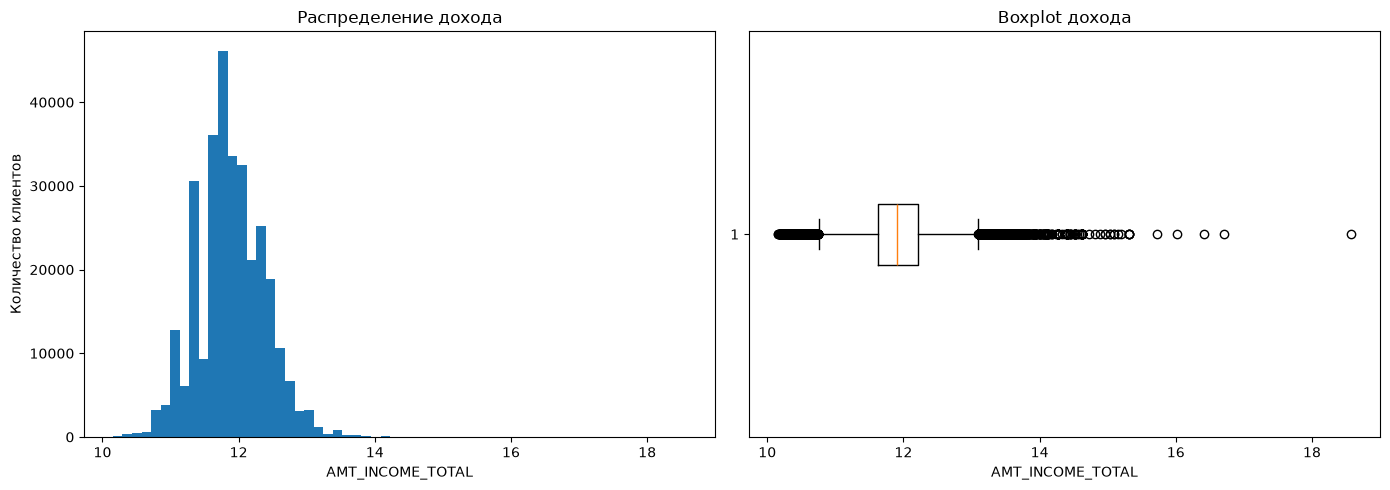

In [7]:
income = df["AMT_INCOME_TOTAL"].dropna()
income_log = np.log1p(income)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(income_log, bins=60)
axes[0].set_title("Распределение дохода")
axes[0].set_xlabel("AMT_INCOME_TOTAL")
axes[0].set_ylabel("Количество клиентов")

axes[1].boxplot(income_log, orientation="horizontal")
axes[1].set_title("Boxplot дохода")
axes[1].set_xlabel("AMT_INCOME_TOTAL")

plt.tight_layout()
plt.show()

### Вспомогательные методы

In [9]:
def get_groups(
    data: pd.DataFrame,
    column: str,
) -> tuple[pd.Series, pd.Series]:
    """Возвращает значения признака для двух групп TARGET."""
    subset = data.loc[
        data["TARGET"].isin([0, 1]),
        ["TARGET", column],
    ].dropna()

    group_0 = subset.loc[subset["TARGET"] == 0, column].astype(float)

    group_1 = subset.loc[subset["TARGET"] == 1, column].astype(float)

    return group_0, group_1

### H1 Доход клиентов связан с фактом дефолта
Признак: AMT_INCOME_TOTAL, группы TARGET = 0 и TARGET = 1.

**Нулевая гипотеза** H<sub>0</sub>: средний доход в двух группах одинаков.\
**Альтернативная гипотеза** H<sub>1</sub>: средний доход различается.\
**Критерии**: t-критерий Уэлча и критерий Манна-Уитни.\
**Зачем сравнивать**: доход имеет асимметричное распределение и выбросы. Критерий Уэлча проверяет различие средних, а Манна-Уитни оценивает различие распределений с учётом рангов.

In [ ]:
income_0, income_1 = get_groups(
    df,
    "AMT_INCOME_TOTAL",
)

welch_result = stats.ttest_ind(
    income_0,
    income_1,
    equal_var=False,
    alternative="two-sided",
)

mw_result = stats.mannwhitneyu(
    income_0,
    income_1,
    alternative="two-sided",
)

income_results = pd.DataFrame(
    {
        "Показатель": [
            "Размер группы без дефолта",
            "Размер группы с дефолтом",
            "Средний доход без дефолта",
            "Средний доход с дефолтом",
            "Медианный доход без дефолта",
            "Медианный доход с дефолтом",
            "Разница средних (дефолт минус отсутствие дефолта)",
            "p-value: Welch",
            "p-value: Mann–Whitney",
        ],
        "Значение": [
            len(income_0),
            len(income_1),
            income_0.mean(),
            income_1.mean(),
            income_0.median(),
            income_1.median(),
            income_1.mean() - income_0.mean(),
            welch_result.pvalue,
            mw_result.pvalue,
        ],
    }
)
display(income_results)

,Показатель,Значение
0,Размер группы без дефолта,282686.0000
1,Размер группы с дефолтом,24825.0000
2,Средний доход без дефолта,169077.7223
3,Средний доход с дефолтом,165611.7609
4,Медианный доход без дефолта,148500.0000
5,Медианный доход с дефолтом,135000.0000
6,Разница средних (дефолт минус отсутствие дефолта),-3465.9614
7,p-value: Welch,0.4650
8,p-value: Mann–Whitney,0.0000


In [13]:
print(f"Mann–Whitney p-value: {mw_result.pvalue:.3e}")

Mann–Whitney p-value: 1.025e-23


Группы сильно различаются по численности, однако разница между средним доходом между группами невелика. Критерий Уэлча (**0,465**) не выявил статистически значимого различия средних доходов. Нет оснований отвергать нулевую гипотезу. При этом критерий Манна-Уитни выявил статистически значимые различия в распределении доходов групп. Доход можно рассматривать как потенциально полезный признак для модели кредитного скоринга, однако результаты сами по себе не доказывают его причинного влияния на дефолт. Имеет смысл рассмотреть производные признаки, например, отношение дохода к сумме кредита, а не сырой AMT_INCOME_TOTAL.

### H2 Возраст клиентов различается между группами дефолта

**Нулевая гипотеза** H<sub>0</sub>: распределение возраста одинаково у клиентов с дефолтом и без него.\
**Альтернативная гипотеза** H<sub>1</sub>: распределения различаются.\
**Критерии**: Манна-Уитни и t-критерий Уэлча.

In [16]:
age_years = -df["DAYS_BIRTH"] / 365.25

group_0, group_1 = get_groups(
    df.assign(AGE_YEARS=age_years),
    "AGE_YEARS",
)

mw_result = stats.mannwhitneyu(
    group_0,
    group_1,
    alternative="two-sided",
)

welch_result = stats.ttest_ind(
    group_0,
    group_1,
    equal_var=False,
    alternative="two-sided",
)

age_descriptive = pd.DataFrame(
    {
        "TARGET = 0": [
            len(group_0),
            group_0.mean(),
            group_0.median(),
        ],
        "TARGET = 1": [
            len(group_1),
            group_1.mean(),
            group_1.median(),
        ],
    },
    index=[
        "Количество клиентов",
        "Средний возраст",
        "Медианный возраст",
    ],
)

display(age_descriptive)

age_tests = pd.DataFrame(
    {
        "Показатель": [
            "Разница средних (TARGET = 1 − TARGET = 0)",
            "Разница медиан (TARGET = 1 − TARGET = 0)",
            "p-value: Welch",
            "p-value: Mann–Whitney",
        ],
        "Значение": [
            group_1.mean() - group_0.mean(),
            group_1.median() - group_0.median(),
            welch_result.pvalue,
            mw_result.pvalue,
        ],
    }
)

display(age_tests)

,TARGET = 0,TARGET = 1
Количество клиентов,282686.0000,24825.0000
Средний возраст,44.1839,40.7524
Медианный возраст,43.4689,39.1020


,Показатель,Значение
0,Разница средних (TARGET = 1 − TARGET = 0),-3.4315
1,Разница медиан (TARGET = 1 − TARGET = 0),-4.3669
2,p-value: Welch,0.0000
3,p-value: Mann–Whitney,0.0000


Разница между возрастом клиентов с дефолтом и без примерно 4 года. Оба критерия выявили статистически значимые различия между группами. Таким образом, гипотеза о различии возрастов поддерживается результатами анализа. Более молодые клиенты чаще допускают дефолт.

### H3 Связь сильных просрочек по предыдущим кредитам с дефолтом по текущей заявке

**Нулевая гипотеза** H<sub>0</sub>: вероятность дефолта по текущей заявке одинакова у клиентов, у которых ранее фиксировались просрочки категории STATUS = '5' и без них.\
**Альтернативная гипотеза** H<sub>1</sub>: вероятности дефолта по текущей заявке различаются между этими группами.\
**Критерий**: критерий хи-квадрат Пирсона для проверки связи между наличием сильной просрочки и дефолтом по текущей заявке.

In [20]:
severe_overdue_loans = bureau_balance.loc[
    bureau_balance["STATUS"].eq("5"),
    "SK_ID_BUREAU",
].drop_duplicates()

severe_overdue_clients = (
    bureau.loc[
        bureau["SK_ID_BUREAU"].isin(severe_overdue_loans),
        "SK_ID_CURR",
    ]
    .drop_duplicates()
)

df_h3 = df[["SK_ID_CURR", "TARGET"]].copy()

df_h3["HAS_SEVERE_OVERDUE"] = df_h3["SK_ID_CURR"].isin(
    severe_overdue_clients
)

contingency_table = pd.crosstab(
    df_h3["HAS_SEVERE_OVERDUE"],
    df_h3["TARGET"],
).reindex(index=[False, True], columns=[0, 1], fill_value=0)

contingency_table.index = [
    "Нет STATUS = 5",
    "Есть STATUS = 5",
]
contingency_table.columns = [
    "TARGET = 0",
    "TARGET = 1",
]

display(contingency_table)

default_rates = (
    contingency_table["TARGET = 1"]
    / contingency_table.sum(axis=1)
    * 100
)

display(
    default_rates.rename("Доля дефолтов, %").to_frame().round(2)
)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print(f"Статистика χ²: {chi2:.4f}")
print(f"p-value: {p_value:.3e}")

if (expected < 5).any():
    print(
        "В некоторых ячейках ожидаемые частоты меньше 5. "
        "Стоит рассмотреть точный критерий Фишера."
    )

if p_value < 0.05:
    print("Отвергаем H0: обнаружена статистически значимая связь.")
else:
    print("Нет оснований отвергнуть H0.")

,TARGET = 0,TARGET = 1
Нет STATUS = 5,280723,24582
Есть STATUS = 5,1963,243


,"Доля дефолтов, %"
Нет STATUS = 5,8.0500
Есть STATUS = 5,11.0200


Статистика χ²: 25.5262
p-value: 4.364e-07
Отвергаем H0: обнаружена статистически значимая связь.


Разница в долях дефолтов по текущей заявки для клиентов с проблемами с займами в прошлом и без составляет почти 3 п.п. Критерий хи-квадрат Пирсона выявил статистически значимую связь между наличием наиболее тяжёлой категории просрочки в предыдущей кредитной истории и дефолтом по текущей заявке. Таким обрзом, нулевая гипотеза отвергается. Признак может быть информативным, однако клиентов, которые имели большие просрочки в прошлом всего чуть больше 2000, поэтому признак охватывает лишь небольшую часть клиентов. В дальнейшем, можно проверить гипотезы STATUS ≥ 3, чтобы расширить долю клиентов, для которых может сработать этот сигнал.

### H4 Уровень образования и дефолт статистически связаны

**Нулевая гипотеза** H<sub>0</sub>: уровень образования и факт дефолта независимы.\
**Альтернативная гипотеза** H<sub>1</sub>: между ними существует статистическая связь.\
**Критерий**: критерий хи-квадрат Пирсона.

In [ ]:
education_summary = (
    df.groupby("NAME_EDUCATION_TYPE", observed=True)["TARGET"]
    .agg(
        clients="count",
        defaults="sum",
        default_rate="mean",
    )
    .sort_values("default_rate", ascending=False)
)

education_summary["default_rate"] *= 100

display(education_summary.round(2))

# Проверяем связь образования с дефолтом
education_table = pd.crosstab(
    df["NAME_EDUCATION_TYPE"],
    df["TARGET"],
)

chi2, p_value, dof, expected = stats.chi2_contingency(
    education_table,
    correction=False,
)

print(f"Статистика χ²: {chi2:.4f}")
print(f"p-value: {p_value:.3e}")

alpha = 0.05

if (expected < 5).any():
    print(
        "Внимание: есть ячейки с ожидаемой частотой меньше 5. "
        "Следует проверить применимость критерия хи-квадрат."
    )

if p_value < alpha:
    print(
        "Отвергаем H₀: обнаружена статистически значимая связь "
        "между уровнем образования и дефолтом."
    )
    print("Доля дефолтов различается между категориями образования.")
else:
    print(
        "Нет оснований отвергнуть H₀: статистически значимая "
        "связь между уровнем образования и дефолтом не обнаружена."
    )

,clients,defaults,default_rate
NAME_EDUCATION_TYPE,,,
Lower secondary,3816,417,10.9300
Secondary / secondary special,218391,19524,8.9400
Incomplete higher,10277,872,8.4800
Higher education,74863,4009,5.3600
Academic degree,164,3,1.8300


Статистика χ²: 1019.2132
p-value: 2.448e-219
Отвергаем H₀: обнаружена статистически значимая связь между уровнем образования и дефолтом.
Доля дефолтов различается между категориями образования.


Наибольшая доля дефолтов наблюдается среди клиентов с неполным средним образованием. Примерно на одном уровне доля дефолтов для клиентов со средне-специальным и незаконченным высшим. Доля дефолтов для людей закончивших вуз или получивших учёную степень снижается, однако последняя в целом, немногочисленна. Для модели можно попробовать объединить Higher Education и Academic degree, чтобы уменьшить дисбаланс между группами.

## Общие выводы

1. Возраст и образование показали себя как сильные и стабильные сигналы
2. Тяжёлая просрочка в прошлом признак редкий, но полезный.
3. Отдельно взятый доход слабый признак, лучше использоваться отношения к сумме кредита, к ежемесячному платежу итд.

### Бонус: метод главных компонент (PCA)

**Зачем применять PCA к этому датасету**
- В `application_train` много числовых признаков (доход, возраст, сумма кредита, аннуитет и т.д.).
- Признаки сильно различаются по масштабу и часто коррелированы.

**План работы**
1. Возьмём только числовые признаки.
2. Заполним пропуски медианой (простое и устойчивое решение).
3. Стандартизируем данные (обязательно для PCA).
4. Посмотрим, сколько компонент нужно, чтобы объяснить 80–90 % дисперсии.
5. Интерпретируем первые 2–3 компоненты по нагрузкам (loadings).

#### Подготовка данных

In [25]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

num_cols = df.select_dtypes(include=["number"]).columns.tolist()
num_cols = [c for c in num_cols if c not in ("SK_ID_CURR", "TARGET")]

X = df[num_cols].copy()

print(f"Числовых признаков: {len(num_cols)}")
print(f"Доля пропусков по признакам (топ-10):")
print((X.isna().mean().sort_values(ascending=False).head(10) * 100).round(2))

Числовых признаков: 104
Доля пропусков по признакам (топ-10):
COMMONAREA_AVG             69.8700
COMMONAREA_MODE            69.8700
COMMONAREA_MEDI            69.8700
NONLIVINGAPARTMENTS_MODE   69.4300
NONLIVINGAPARTMENTS_AVG    69.4300
NONLIVINGAPARTMENTS_MEDI   69.4300
LIVINGAPARTMENTS_MEDI      68.3500
LIVINGAPARTMENTS_MODE      68.3500
LIVINGAPARTMENTS_AVG       68.3500
FLOORSMIN_AVG              67.8500
dtype: float64


#### Заполнение пропусков, стандартизация, PCA

In [26]:
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

pca_full = PCA()
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumsum = np.cumsum(explained)

print("Доля дисперсии, объясняемая первыми компонентами:")
for k in [5, 10, 15, 20, 30]:
    if k <= len(explained):
        print(f"  {k:2d} компонент → {cumsum[k-1]*100:.1f} %")

Доля дисперсии, объясняемая первыми компонентами:
   5 компонент → 32.4 %
  10 компонент → 44.7 %
  15 компонент → 53.4 %
  20 компонент → 60.0 %
  30 компонент → 70.7 %


#### График объяснённой дисперсии

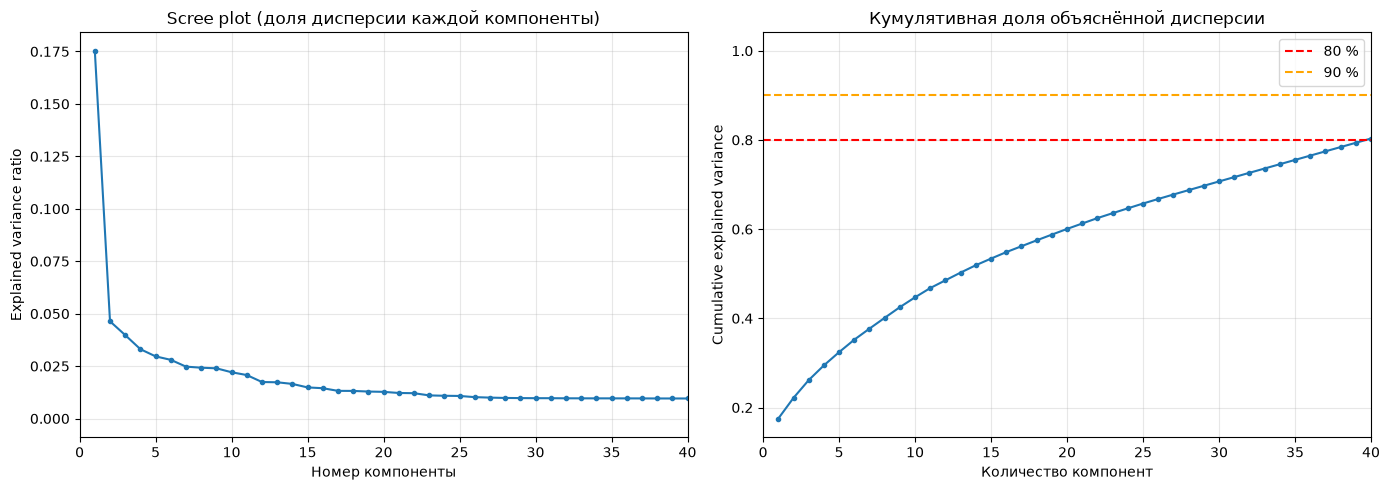

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(explained) + 1), explained, marker="o", markersize=3)
axes[0].set_title("Scree plot (доля дисперсии каждой компоненты)")
axes[0].set_xlabel("Номер компоненты")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_xlim(0, 40)
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, len(cumsum) + 1), cumsum, marker="o", markersize=3)
axes[1].axhline(0.8, color="red", linestyle="--", label="80 %")
axes[1].axhline(0.9, color="orange", linestyle="--", label="90 %")
axes[1].set_title("Кумулятивная доля объяснённой дисперсии")
axes[1].set_xlabel("Количество компонент")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_xlim(0, 40)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Интерпретация первых компонент

In [28]:
n_comp = 3
pca = PCA(n_components=n_comp)
pca.fit(X_scaled)

loadings = pd.DataFrame(
    pca.components_.T,
    index=num_cols,
    columns=[f"PC{i+1}" for i in range(n_comp)],
)

print("Топ-8 признаков с наибольшими |нагрузками| по каждой компоненте:\n")

for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(8)
    print(f"=== {pc} (объясняет {pca.explained_variance_ratio_[int(pc[2])-1]*100:.1f} % дисперсии) ===")
    display(
        pd.DataFrame({
            "Признак": top.index,
            "Нагрузка": loadings.loc[top.index, pc].values,
            "|Нагрузка|": top.values,
        }).round(3)
    )
    print()

Топ-8 признаков с наибольшими |нагрузками| по каждой компоненте:

=== PC1 (объясняет 17.5 % дисперсии) ===


,Признак,Нагрузка,|Нагрузка|
0,LIVINGAREA_AVG,0.2180,0.2180
1,LIVINGAREA_MEDI,0.2180,0.2180
2,APARTMENTS_MEDI,0.2170,0.2170
3,APARTMENTS_AVG,0.2170,0.2170
4,LIVINGAREA_MODE,0.2140,0.2140
5,TOTALAREA_MODE,0.2140,0.2140
6,APARTMENTS_MODE,0.2130,0.2130
7,ELEVATORS_MEDI,0.2050,0.2050



=== PC2 (объясняет 4.6 % дисперсии) ===


,Признак,Нагрузка,|Нагрузка|
0,ENTRANCES_MODE,0.2830,0.2830
1,ENTRANCES_MEDI,0.2780,0.2780
2,ENTRANCES_AVG,0.2760,0.2760
3,FLOORSMIN_MEDI,-0.2610,0.2610
4,FLOORSMIN_AVG,-0.2610,0.2610
5,FLOORSMIN_MODE,-0.2560,0.2560
6,FLOORSMAX_MEDI,-0.2300,0.2300
7,FLOORSMAX_AVG,-0.2300,0.2300



=== PC3 (объясняет 4.0 % дисперсии) ===


,Признак,Нагрузка,|Нагрузка|
0,FLAG_EMP_PHONE,0.4130,0.4130
1,DAYS_EMPLOYED,-0.4120,0.4120
2,DAYS_BIRTH,0.3630,0.3630
3,FLAG_DOCUMENT_6,-0.3160,0.3160
4,REG_CITY_NOT_WORK_CITY,0.2470,0.2470
5,CNT_CHILDREN,0.2090,0.2090
6,LIVE_CITY_NOT_WORK_CITY,0.2090,0.2090
7,CNT_FAM_MEMBERS,0.2040,0.2040


Анализ главных компонент показал, что первая компонента преимущественно связана с характеристиками жилья, вторая с количеством подъездов и этажностью зданий. Третья объединяет признаки занятости, возраста и семейного состава. На scree plot наблюдается плато примерно полсле 20 компонент, однако для объяснения 80% дисперсии нужно в два раза больше. Это говорит о том, что информация распределена между многими признаками, поэтому при сокращении их количества теряется часть информации об исходных данных. PCA ищет направление максмальной дисперсии признаков, а не максимальной важности для TARGET, поэтому компоненту, объясняющую большую долю дисперсии нельзя автоматически считать более полезной для прогнозирования дефолта. Необходимо сравнить качество модели на исходных данных и на представлениях с 20, 40 компонентами.